In [1]:
import sys, os, warnings
import numpy as np
import scipy as sp
import pandas as pd
import nibabel as nib
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from brainsmash.mapgen.base import Base

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])
sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/nctpy/src'])

from src.plotting import plot_repeated_measures_violins, plot_subject_level_violins, plot_brain_surface_data
from src.notebook import load_notebook_data

from src.timescales import create_ints_dataframe_custom_grouping, convert_data_dict, average_data_dict_converted
from snaplab_tools.plotting.plotting import plot_correlation, plot_correlation_unity
from snaplab_tools.plotting.utils import get_my_colors
from snaplab_tools.utils import winsorize

# Load data

In [2]:
dataset = 'HCP-YA'
which_modality = 'FMRI'
meg_freq = '_lp-0.5hz'
use_7t = True
output_type = 'timescale_zero_crossing_robust_nc3'
notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   use_7t=use_7t, output_type=output_type)

Initialized DataLoader for dataset: HCP-YA
Base directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
Raw data directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
Derivatives data directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded behavioral data: 1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
timescale_zero_crossing_robust_nc3


Loading timescale_zero_crossing_robust_nc3: 100%|██████████| 4238/4238 [00:00<00:00, 9123.98it/s]


4238


Loading timescale_zero_crossing_robust_nc3_resids: 100%|██████████| 4238/4238 [00:00<00:00, 9191.64it/s]


4238
Number of subjects: 163
Loading connectivity data...
	sub-380036 not found
	sub-971160 not found
Loading myelin data...


In [3]:
# get key outputs for this notebook
timescales_processor = notebook_data['timescales_processor']
data_dict = notebook_data['data_dict']
results_dir = notebook_data['results_dir']

dict_neuro = notebook_data['supporting_data']['dict_neuro']
distance_matrix = notebook_data['supporting_data']['distance_matrix']
gene_expression_nanmask = notebook_data['supporting_data']['gene_expression_nanmask']
yeo_systems = notebook_data['supporting_data']['yeo_systems']

adjacency_matrices = notebook_data['adjacency_matrices']
myelin = notebook_data['myelin']

print(data_dict.keys())
print(dict_neuro.keys())

dict_keys(['sub-100610_task-rfMRIREST1LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-rfMRIREST1RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-rfMRIREST2LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-rfMRIREST2RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-tfMRIWMLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIWMRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIEMOTIONLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIEMOTIONRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIGAMBLINGLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIGAMBLINGRL_space-fsLR

In [4]:
timescales_processor.scan_registry.head()

,scan_string,sub,task,space,seg,ses,modality,tr,condition
0,sub-100610_task-rfMRIREST1LR_space-fsLR_seg-Sc...,100610,rfMRIREST1LR,fsLR,Schaefer4007,1,MRI3T,0.72,rest
1,sub-100610_task-rfMRIREST1RL_space-fsLR_seg-Sc...,100610,rfMRIREST1RL,fsLR,Schaefer4007,1,MRI3T,0.72,rest
2,sub-100610_task-rfMRIREST2LR_space-fsLR_seg-Sc...,100610,rfMRIREST2LR,fsLR,Schaefer4007,1,MRI3T,0.72,rest
3,sub-100610_task-rfMRIREST2RL_space-fsLR_seg-Sc...,100610,rfMRIREST2RL,fsLR,Schaefer4007,1,MRI3T,0.72,rest
4,sub-100610_task-tfMRIWMLR_space-fsLR_seg-Schae...,100610,tfMRIWMLR,fsLR,Schaefer4007,1,MRI3T,0.72,task


In [5]:
subject_ids = timescales_processor.scan_registry['sub'].unique()
n_subs = len(subject_ids)
print(f'Number of subjects: {n_subs}')

Number of subjects: 163


In [6]:
data_dict_converted = convert_data_dict(data_dict, timescales_processor.scan_registry)

rfMRIREST1LR (163, 400)
rfMRIREST1RL (163, 400)
rfMRIREST2LR (163, 400)
rfMRIREST2RL (163, 400)
tfMRIWMLR (163, 400)
tfMRIWMRL (163, 400)
tfMRIEMOTIONLR (163, 400)
tfMRIEMOTIONRL (163, 400)
tfMRIGAMBLINGLR (163, 400)
tfMRIGAMBLINGRL (163, 400)
tfMRILANGUAGELR (163, 400)
tfMRILANGUAGERL (163, 400)
tfMRIRELATIONALLR (163, 400)
tfMRIRELATIONALRL (163, 400)
tfMRISOCIALLR (163, 400)
tfMRISOCIALRL (163, 400)
tfMRIMOTORLR (163, 400)
tfMRIMOTORRL (163, 400)
rfMRIREST17TPA (163, 400)
rfMRIREST27TAP (163, 400)
rfMRIREST37TPA (163, 400)
rfMRIREST47TAP (163, 400)
tfMRIMOVIE17TAP (163, 400)
tfMRIMOVIE27TPA (163, 400)
tfMRIMOVIE37TPA (163, 400)
tfMRIMOVIE47TAP (163, 400)


In [7]:
data_dict_converted = average_data_dict_converted(data_dict_converted, average_3t_tasks=True, average_7t_movies=True, average_all_rest=True)

Applying scan averaging to centiles dictionary...
  Averaged 8 rest scans (3T and 7T) into: Rest
    Shape: (163, 400)
  Averaged 14 3T task scans into: Tasks
    Shape: (163, 400)
  Averaged 4 7T movie scans into: Movies
    Shape: (163, 400)

Final dictionary contains 3 scan types:
  Rest: (163, 400)
  Tasks: (163, 400)
  Movies: (163, 400)

Applied averaging for: all rest, 3T all tasks, 7T movies


# Subject-level analyses: Whole-brain spatial correlation analysis

In [8]:
if dataset == 'HCP-YA':
    neuro_cols = ['Myelin', 'Gene (PC1)', 'Strength']
    # neuro_cols = ['Gene (PC1)', 'Myelin', 'Strength', 'Gene_EI_ratio']
    # neuro_cols = ['Gene (PC1)', 'Myelin', 'SC_Degree']
    # neuro_cols = ['Gene_PVALB', 'Gene_GRIA1', 'Gene_GRIN2A', 'Gene_GABRA1', 'Gene_GABRA3']
    # neuro_cols = ['Gene_GABRA1', 'Gene_GABRA2', 'Gene_GABRA3', 'Gene_GABRA4', 'Gene_GABRA5']
else:
    neuro_cols = ['Gene (PC1)']

In [9]:
df_corr = pd.DataFrame(index=subject_ids)
df_corr.index.name = 'subject_ids'
for neuro_col in neuro_cols:
    for int_col in data_dict_converted.keys():
        print(neuro_col)
        for i in tqdm(np.arange(n_subs)):
            subject_id = subject_ids[i]
            if 'Gene' in neuro_col:
                corr = sp.stats.pearsonr(data_dict_converted[int_col][i][gene_expression_nanmask], dict_neuro[neuro_col][gene_expression_nanmask])
            elif 'Myelin' in neuro_col:
                corr = sp.stats.pearsonr(data_dict_converted[int_col][i], myelin[:, i])
            elif 'Strength' in neuro_col:
                strength_tmp = np.log(adjacency_matrices[:, :, i].sum(axis=0))
                corr = sp.stats.pearsonr(data_dict_converted[int_col][i], strength_tmp)
            else:
                corr = sp.stats.pearsonr(data_dict_converted[int_col][i], dict_neuro[neuro_col])

            # column_label = 'corr({0},{1})'.format(neuro_col.lower(), int_col.lower())
            column_label = '({0},{1})'.format(neuro_col.lower(), int_col.lower())
            df_corr.loc[subject_id, column_label] = corr[0]

Myelin


100%|██████████| 163/163 [00:00<00:00, 7373.11it/s]


Myelin


100%|██████████| 163/163 [00:00<00:00, 5711.26it/s]


Myelin


...

100%|██████████| 163/163 [00:00<00:00, 1689.31it/s]


Strength


100%|██████████| 163/163 [00:00<00:00, 1735.81it/s]


Strength


100%|██████████| 163/163 [00:00<00:00, 1735.43it/s]


In [10]:
df_corr.columns

Index(['(myelin,rest)', '(myelin,tasks)', '(myelin,movies)',
       '(gene (pc1),rest)', '(gene (pc1),tasks)', '(gene (pc1),movies)',
       '(strength,rest)', '(strength,tasks)', '(strength,movies)'],
      dtype='object')

In [11]:
df_corr.head()

,"(myelin,rest)","(myelin,tasks)","(myelin,movies)","(gene (pc1),rest)","(gene (pc1),tasks)","(gene (pc1),movies)","(strength,rest)","(strength,tasks)","(strength,movies)"
subject_ids,,,,,,,,,
100610,-0.315018,-0.241266,-0.225163,-0.112566,0.052828,-0.112959,-0.006342,0.028421,-0.106441
102311,-0.240422,-0.456335,-0.356941,-0.125757,-0.205225,-0.250480,0.088003,-0.094972,0.026684
102816,-0.429234,-0.247045,-0.116425,-0.221980,-0.057979,-0.031117,0.102717,0.082442,0.026733
104416,-0.408636,-0.079850,-0.141626,-0.247912,0.190544,0.083813,0.181252,0.036368,0.065049
105923,-0.212734,-0.211384,-0.332650,-0.107825,-0.032780,-0.189717,0.093719,-0.079691,-0.033972


In [12]:
my_colors = get_my_colors(cat_trio=False, as_list=True)

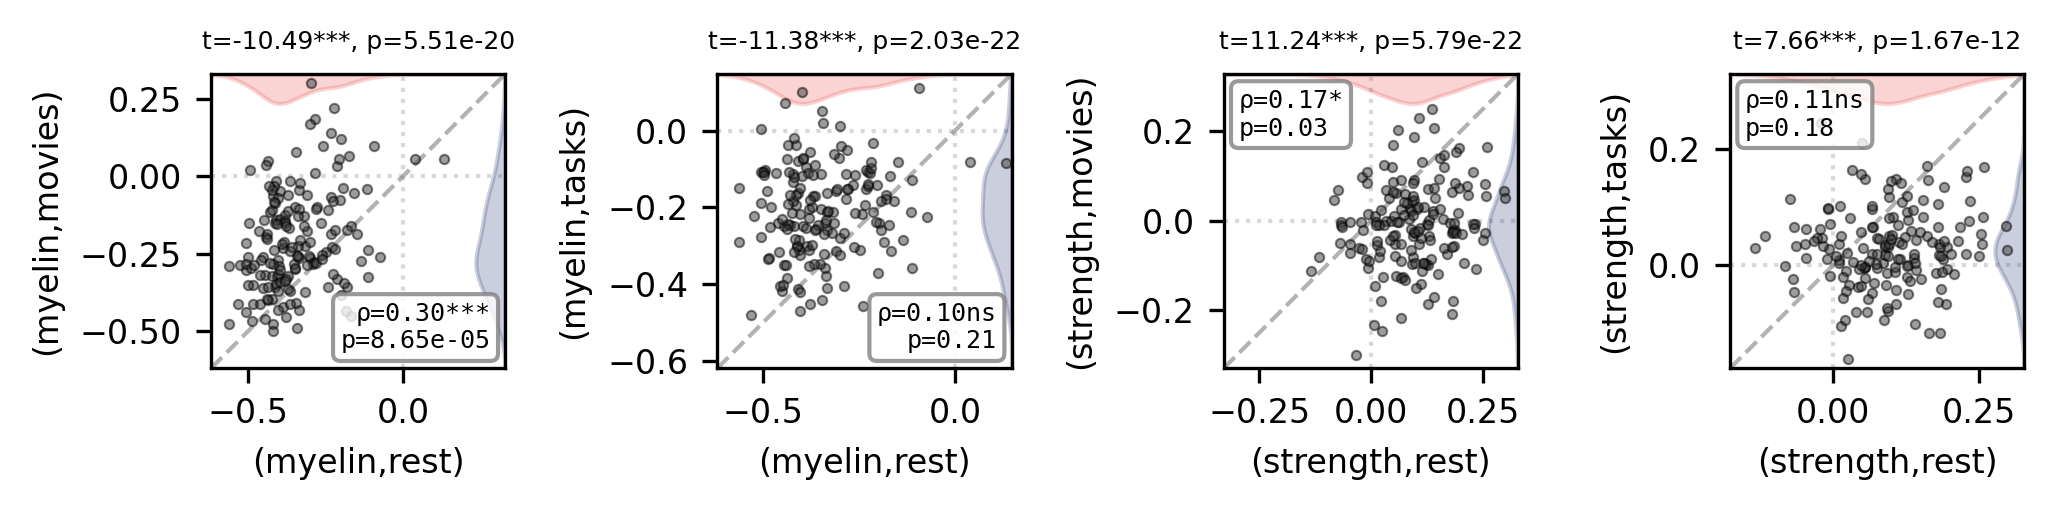

In [13]:
if dataset == 'HCP-YA':
    try:
        fig, axes = plt.subplots(nrows=1, ncols=4, sharex=False, sharey=False, figsize=(7.5, 1.5), dpi=300)
        plot_correlation_unity(df_corr['(myelin,rest)'], df_corr['(myelin,movies)'], axes[0],
                            marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                            show_marginals=True, show_correlation=True, correlation_type='spearman', grid=False, size=5, fontsize=8)
        plot_correlation_unity(df_corr['(myelin,rest)'], df_corr['(myelin,tasks)'], axes[1],
                            marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                            show_marginals=True, show_correlation=True, correlation_type='spearman', grid=False, size=5, fontsize=8)
        plot_correlation_unity(df_corr['(strength,rest)'], df_corr['(strength,movies)'], axes[2],
                            marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                            show_marginals=True, show_correlation=True, correlation_type='spearman', grid=False, size=5, fontsize=8)
        plot_correlation_unity(df_corr['(strength,rest)'], df_corr['(strength,tasks)'], axes[3],
                            marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                            show_marginals=True, show_correlation=True, correlation_type='spearman', grid=False, size=5, fontsize=8)
        # plt.tight_layout()
        plt.tight_layout(pad=0, w_pad=-5, h_pad=0)
        fig.savefig(os.path.join(results_dir, 'neuroantomy_INTs_correlations_unity.png'), bbox_inches='tight', dpi=300, transparent=True)
        plt.show()
    except:
        fig, axes = plt.subplots(nrows=1, ncols=2, sharex=False, sharey=False, figsize=(5, 1.5), dpi=300)
        plot_correlation_unity(df_corr['(myelin,rest)'], df_corr['(myelin,tasks)'], axes[0],
                            marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                            show_marginals=True, show_correlation=True, correlation_type='spearman', grid=False, size=5, fontsize=8)
        plot_correlation_unity(df_corr['(strength,rest)'], df_corr['(strength,tasks)'], axes[1],
                            marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                            show_marginals=True, show_correlation=True, correlation_type='spearman', grid=False, size=5, fontsize=8)
        # plt.tight_layout()
        plt.tight_layout(pad=0, w_pad=-5, h_pad=0)
        fig.savefig(os.path.join(results_dir, 'neuroantomy_INTs_correlations_unity.png'), bbox_inches='tight', dpi=300, transparent=True)
        plt.show()